In [1]:
%run "///home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/impport_packages.ipynb"    #import all necessary packages - numpy, pandas etc
%run "///home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/simulation_class.ipynb"    #import all necessary packages - numpy, pandas etc


In [30]:
def create_world_single(rho,m, max_gen):
    
    # Define rho and m grid
    rho = rho
    m = m
    alpha = (1 - rho) * (1 - m)
    beta = (1 - rho) * m


    # Flatten and create DataFrame
    data_env = np.array([rho, m, alpha, beta])

    n_gen = max_gen


    opt = np.array([0, 1])

    Env = np.zeros(n_gen, dtype=int)
    p = np.random.uniform(0, 1, n_gen)

    for g in range(n_gen - 1):
        if p[g] < (alpha if Env[g] == 0 else beta):
            Env[g+1] = 1 - Env[g]  # Flip state
        else:
            Env[g+1] = Env[g]       # Stay same

    env_values = opt[Env] # final result

    
    rho_m_alpha_beta = data_env

    # Equilibrium stats
    return rho_m_alpha_beta, env_values

In [34]:
rho_val_0, m_val_0 = 0.99, 0.95
rho_val_1, m_val_1 = 0.75, 0.5
rho_val_2, m_val_2 = 0.1,0.5
rho_val_3, m_val_3 = -0.75, 0.5


In [43]:
maxgen = 30

rho_m_alpha_beta_0, single_scenario_0 = create_world_single(rho =rho_val_0, m= m_val_0, max_gen= maxgen)  # Shape: (10000,)

# First create single scenario,


rho_m_alpha_beta_1, single_scenario_1 = create_world_single(rho =rho_val_1, m= m_val_1, max_gen= maxgen)  # Shape: (10000,)

# First create single scenario,

rho_m_alpha_beta_2, single_scenario_2 = create_world_single(rho =rho_val_2, m= m_val_2, max_gen= maxgen)  # Shape: (10000,)


rho_m_alpha_beta_3, single_scenario_3 = create_world_single(rho =rho_val_3, m= m_val_3, max_gen= maxgen)  # Shape: (10000,)

single_scenario = [single_scenario_0,single_scenario_1, single_scenario_2, single_scenario_3]
rho_m_alpha_beta = [rho_m_alpha_beta_0, rho_m_alpha_beta_1,rho_m_alpha_beta_2, rho_m_alpha_beta_3 ]



In [14]:
rho_m_alpha_beta[0][0]

np.float64(0.99)

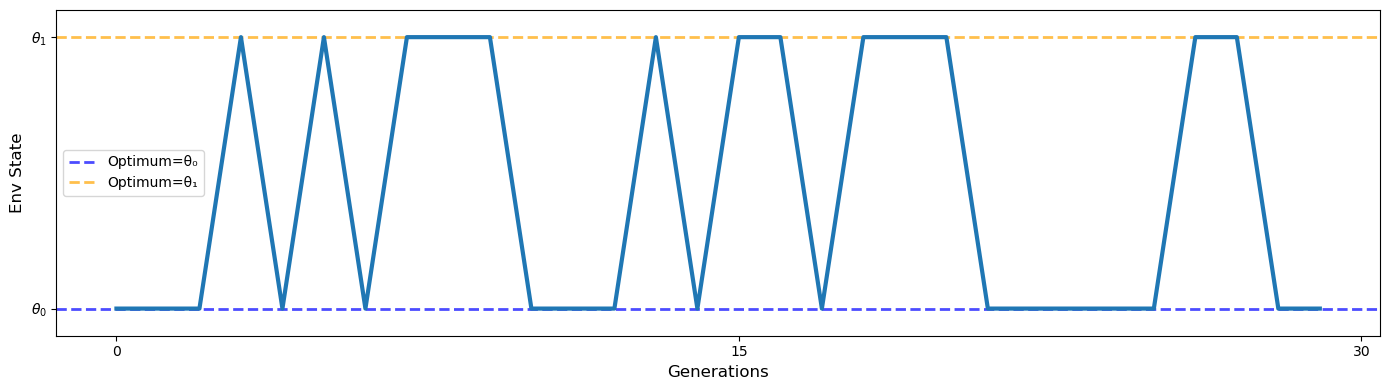

In [46]:
fig, ax = plt.subplots(figsize=(14, 4))

ax.axhline(y=0, color='blue', linestyle='--', linewidth=2, alpha=0.7, label='Optimum=θ₀')
ax.axhline(y=1, color='orange', linestyle='--', linewidth=2, alpha=0.7, label='Optimum=θ₁')


ax.plot(single_scenario[2], linewidth=3)


#ax.set_title(rf"$\rho$={rho_m_alpha_beta[0][0]}, m={rho_m_alpha_beta[0][1]}", fontsize=16)
ax.set_xlabel("Generations", fontsize=12)
ax.set_ylabel("Env State", fontsize=12)


ax.set_ylim(-0.1, 1.1)
ax.set_yticks([0, 1])
ax.set_xticks([0,15,30])
ax.set_yticklabels([r'$\theta_0$', r'$\theta_1$'])
ax.tick_params(axis='both', labelsize=10)
ax.legend()

plt.tight_layout()
plt.savefig(
    "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/"
    "Evolve_Transgenerational_memory/Plot_results/plot_report/figures_svg/10k/flucts_schem.png",
    dpi=1000,
    transparent= True
)
plt.show()

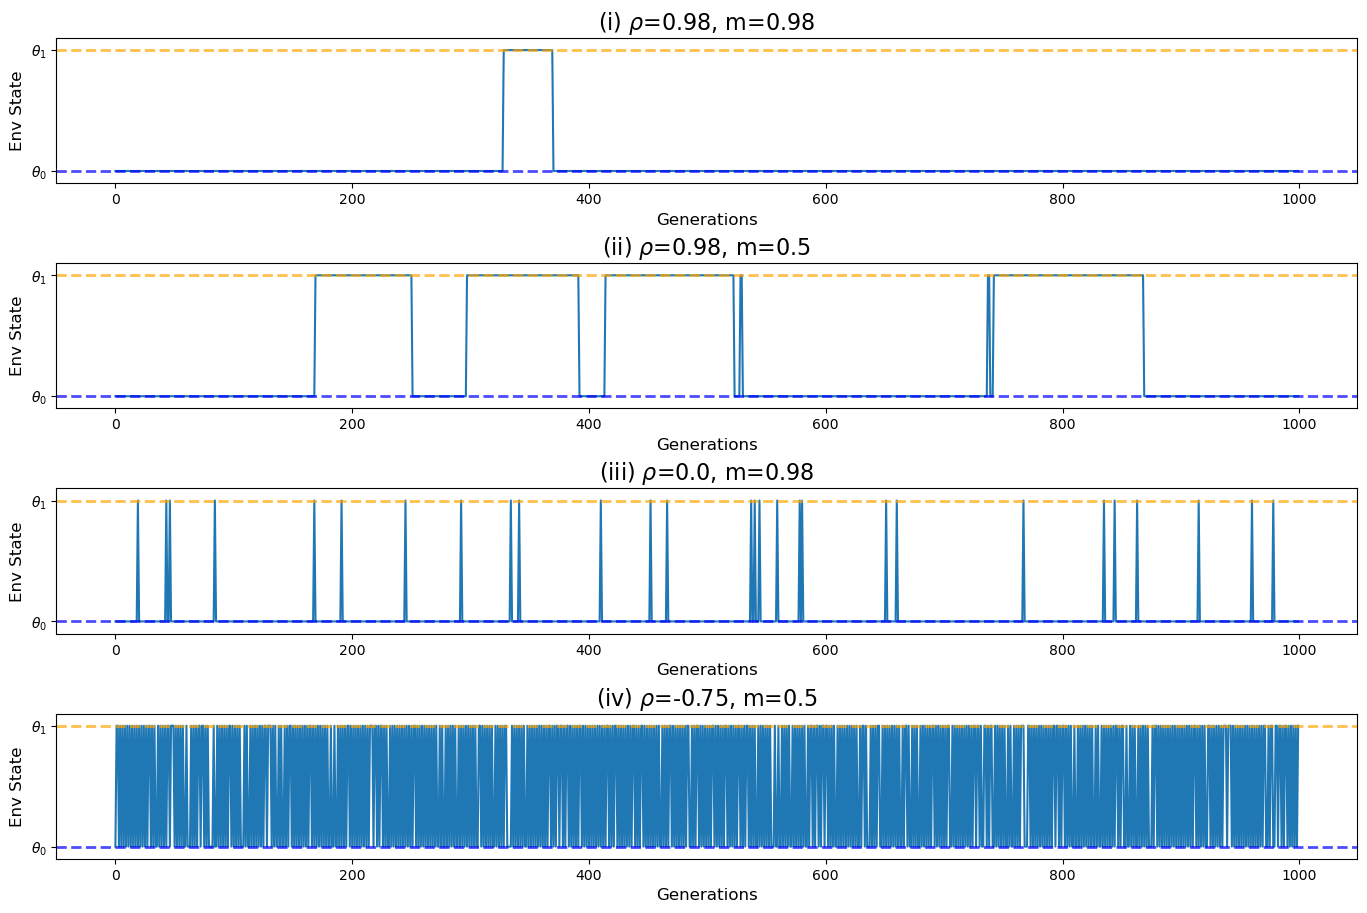

In [15]:
fig, axes = plt.subplots(4, 1, figsize=(14, 10))
axis_label_size = 12
sub_heads = ['i', 'ii', 'iii', 'iv']
for i, scenario in enumerate(single_scenario):
    axes[i].plot(scenario, linewidth=1.5) 
    axes[i].set_title(rf"({sub_heads[i]}) $\rho$={rho_m_alpha_beta[i][0]}, m={rho_m_alpha_beta[i][1]}", fontsize=16)
    axes[i].set_xlabel("Generations", fontsize=axis_label_size)
    axes[i].set_ylabel("Env State", fontsize=axis_label_size)
    axes[i].axhline(y=0, color='blue', linestyle='--', linewidth=2, alpha=0.7, label='Optimum=θ₀')
    axes[i].axhline(y=1, color='orange', linestyle='--', linewidth=2, alpha=0.7, label='Optimum=θ₁')
    axes[i].set_ylim(-0.1, 1.1)
    axes[i].tick_params(axis='both', labelsize=10)
    
    # Remove all y-ticks and set only 0 and 1 with custom labels
    axes[i].set_yticks([0, 1])
    axes[i].set_yticklabels([r'$\theta_0$', r'$\theta_1$'])
    
plt.tight_layout()
plt.subplots_adjust(top=0.88, left=0.06)
plt.savefig("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Plot_results/plot_report/figures_svg/10k/flucts.png", dpi=1000)
plt.show()

In [21]:

single_scenario = [single_scenario_0,single_scenario_1]
rho_m_alpha_beta = [rho_m_alpha_beta_0, rho_m_alpha_beta_1 ]



In [59]:
np.tile(np.repeat([0, 1], 5), (n_gen // 10) + 1)[:n_gen]

array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0])

In [60]:

n_gen = 35

single_scenario = [
    np.array([g % 2 for g in range(1, n_gen + 1)]),                 # generation 1 to 35
    np.tile(np.repeat([0, 1], 5), (n_gen // 10) + 1)[:n_gen]        # 5 gens each env
]

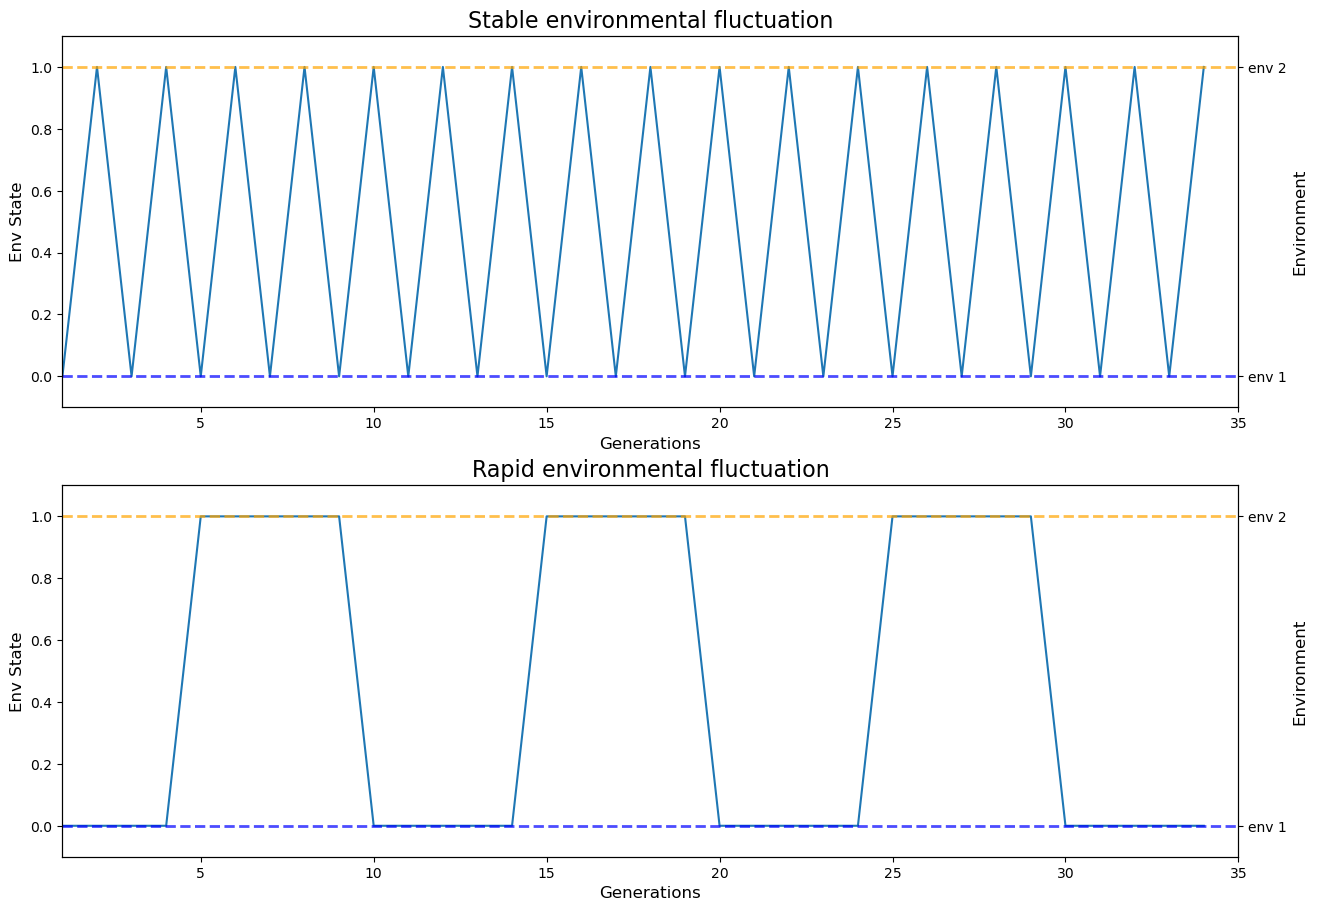

In [63]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
axis_label_size = 12
sub_heads = ['i', 'ii']
label = ['Stable', 'Rapid']
x = np.arange(0, n_gen )

for i, scenario in enumerate(single_scenario):
    ax = axes[i]
    ax.plot(x, scenario, linewidth=1.5)

    ax.set_title(rf"{label[i]} environmental fluctuation", fontsize=16)
    ax.set_xlabel("Generations", fontsize=axis_label_size)
    ax.set_ylabel("Env State", fontsize=axis_label_size)
    ax.axhline(y=0, color='blue', linestyle='--', linewidth=2, alpha=0.7, label='Optimum = 0')
    ax.axhline(y=1, color='orange', linestyle='--', linewidth=2, alpha=0.7, label='Optimum = 1')
    ax.set_ylim(-0.1, 1.1)
    ax.set_xlim(1, n_gen)
    ax.tick_params(axis='both', labelsize=10)

    ax_r = ax.twinx()
    ax_r.set_ylim(ax.get_ylim())
    ax_r.set_yticks([0, 1])
    ax_r.set_yticklabels(['env 1', 'env 2'])
    ax_r.set_ylabel("Environment", fontsize=axis_label_size)
    ax_r.tick_params(axis='y', labelsize=10)
    ax_r.grid(False)

plt.tight_layout()
plt.savefig(f'/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/Flutuations.pdf')
plt.subplots_adjust(top=0.88, left=0.06, right=0.90)
plt.show()